In [1]:
import sys
print(sys.executable)
%pip install pandas numpy matplotlib seaborn

/usr/bin/python3
Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 KB 5.3 MB/s eta 0:00:00 MB/s eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

df = pd.read_csv("dados_investimento_e_vagas_ifes.csv").sort_values('ano').reset_index(drop=True)

### Critério

Considerei **ano crítico** aquele em que as duas condições acontecem ao mesmo tempo:

1. o investimento em assistência estudantil **caiu ou ficou praticamente parado** (variação de até +1% em relação ao ano anterior);
2. o número de vagas de estudantes **aumentou** no mesmo ano.

O limite de 1% para "estagnação" é uma escolha minha. 1996 fica de fora porque não há ano anterior para comparar.

In [3]:
# Variação percentual ano a ano (o primeiro ano, 1996, não tem ano anterior e fica como NaN)
df['var_assistencia_pct'] = df['investimento_assistencia_estudantil_bilhoes_brl'].pct_change() * 100
df['var_investimento_pct'] = df['investimento_total_ifes_bilhoes_brl'].pct_change() * 100
df['var_vagas_pct'] = df['num_vagas_estudantes'].pct_change() * 100

In [7]:
LIMITE_ESTAGNACAO = 1.0  # variação anual da assistência <= 1% conta como corte ou estagnação

anos_criticos = df.groupby('ano').filter(
    lambda g: (g['var_assistencia_pct'] <= LIMITE_ESTAGNACAO).all()
              and (g['var_vagas_pct'] > 0).all()
)

df['ano_critico'] = df['ano'].isin(anos_criticos['ano'])

anos_criticos[['ano', 'investimento_assistencia_estudantil_bilhoes_brl',
               'var_assistencia_pct', 'num_vagas_estudantes', 'var_vagas_pct']].round(2)

,ano,investimento_assistencia_estudantil_bilhoes_brl,var_assistencia_pct,num_vagas_estudantes,var_vagas_pct
1,1997,0.02,0.00,351400,2.72
3,1999,0.03,0.00,375200,3.39
5,2001,0.04,0.00,410500,4.77
19,2015,1.28,-3.03,1184000,2.78
20,2016,1.29,0.78,1221000,3.12
21,2017,1.25,-3.10,1264000,3.52
22,2018,1.22,-2.40,1298000,2.69
23,2019,1.18,-3.28,1312000,1.08
24,2020,1.15,-2.54,1324000,0.91
26,2022,0.98,-10.09,1329000,0.83


### Resultado

Foram identificados **11 anos críticos**: 1997, 1999, 2001, 2015 a 2020, 2022 e 2026.

- Em 1997, 1999 e 2001 o valor ficou parado em R$ 0,02, 0,03 e 0,04 bilhão. Como são valores muito pequenos e com duas casas decimais, parte dessa "estagnação" pode ser arredondamento.
- 2015 a 2020 formam o único bloco longo: seis anos seguidos sem crescimento real da assistência, com vagas ainda subindo.
- 2021 ficou de fora de propósito: a assistência caiu 5,2%, mas as vagas também recuaram (-0,45%), então não cumpre a condição 2.

In [8]:
# Agrupa anos críticos consecutivos em faixas para o sombreamento
bloco = (df['ano_critico'] != df['ano_critico'].shift()).cumsum()
faixas = (
    df[df['ano_critico']]
    .groupby(bloco[df['ano_critico']])['ano']
    .agg(['min', 'max'])
)
faixas

,min,max
ano_critico,,
2,1997,1997
4,1999,1999
6,2001,2001
8,2015,2020
10,2022,2022
12,2026,2026


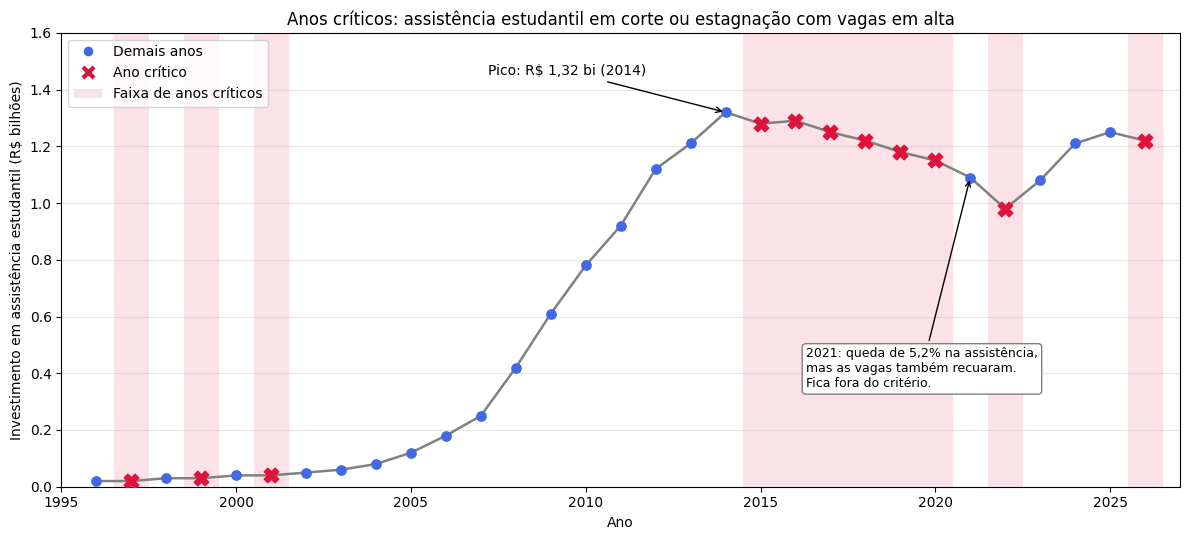

In [6]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

COR_CRITICO = 'crimson'
COR_NORMAL = 'royalblue'
col = 'investimento_assistencia_estudantil_bilhoes_brl'
normais = df[~df['ano_critico']]
criticos = df[df['ano_critico']]

fig, ax = plt.subplots(figsize=(12, 5.5))

# 1) sombreamento de fundo nas faixas críticas
for _, f in faixas.iterrows():
    ax.axvspan(f['min'] - 0.5, f['max'] + 0.5, color=COR_CRITICO, alpha=0.12, linewidth=0)

# 2) linha do tempo + marcadores (formato e cor diferentes nos anos críticos)
ax.plot(df['ano'], df[col], color='gray', linewidth=1.8, zorder=2)
ax.scatter(normais['ano'], normais[col], color=COR_NORMAL, s=45, zorder=3)
ax.scatter(criticos['ano'], criticos[col], color=COR_CRITICO, marker='X', s=110, zorder=4)

# 3) setas anotando dois pontos-chave
pico = df.loc[df[col].idxmax()]
ax.annotate(
    f"Pico: R$ {pico[col]:.2f} bi ({int(pico['ano'])})".replace('.', ','),
    xy=(pico['ano'], pico[col]), xytext=(2007.2, 1.45),
    arrowprops=dict(arrowstyle='->', color='black'), fontsize=10
)
ax.annotate(
    "2021: queda de 5,2% na assistência,\nmas as vagas também recuaram.\nFica fora do critério.",
    xy=(2021, df.loc[df['ano'] == 2021, col].iloc[0]), xytext=(2016.3, 0.35),
    arrowprops=dict(arrowstyle='->', color='black'), fontsize=9,
    bbox=dict(boxstyle='round', fc='white', ec='gray')
)

ax.set_ylim(0, 1.6)
ax.set_xlim(1995, 2027)
ax.set_title('Anos críticos: assistência estudantil em corte ou estagnação com vagas em alta')
ax.set_xlabel('Ano')
ax.set_ylabel('Investimento em assistência estudantil (R$ bilhões)')
ax.grid(axis='y', alpha=0.3)

ax.legend(handles=[
    Line2D([], [], marker='o', color='w', markerfacecolor=COR_NORMAL, markersize=8, label='Demais anos'),
    Line2D([], [], marker='X', color='w', markerfacecolor=COR_CRITICO, markersize=11, label='Ano crítico'),
    Patch(facecolor=COR_CRITICO, alpha=0.12, label='Faixa de anos críticos'),
], loc='upper left')

plt.tight_layout()
plt.show()

### Decisão de visualização

Usei a **linha do tempo da assistência estudantil** com três camadas de destaque:

- **Marcadores em X vermelhos** nos anos críticos e círculos azuis nos demais. A mudança de forma, e não só de cor, mantém o destaque legível para quem tem daltonismo ou imprime em preto e branco.
- **Sombreamento de fundo** nas faixas de anos críticos consecutivos. O marcador identifica cada ano; o sombreamento mostra que 2015-2020 é um período contínuo, não seis pontos isolados.
- **Duas setas anotadas**: o pico de 2014, que serve de referência para medir a queda, e 2021, que explica por que um ano com queda na assistência não foi marcado.

O eixo y começa em zero para que a queda de 2014 a 2022 seja lida na proporção correta. A legenda usa só os três elementos visuais que de fato aparecem no gráfico.